In [1]:
using Pkg

In [50]:
LINE_WIDTH = 4

4

In [47]:
import XLSX
using DataFrames
using Plots
using Turing
using Distributions
using MCMCChains
using DynamicPPL
using GaussianMixtures
using Distributions  # for the Normal distribution
using KernelDensity
using PyCall, RCall
using QuadGK

In [3]:
run(`ls`)

AveragedOriginalMeasurements_all_graphs.xlsx
Binned_Energies.xlsx
Data_normalised.xlsx
dirichlet_fit.py
JuliaRefactored.ipynb
medicalHeat.ipynb
med_trials_V8.ipynb
med_trials_V8-refactor.ipynb
UsedDataEntrBin_original.xlsx


Process(`ls`, ProcessExited(0))

In [4]:
UsedDataEntrBin_original = XLSX.readxlsx("Data_normalised.xlsx")

XLSXFile("Data_normalised.xlsx") containing 3 Worksheets
            sheetname size          range        
-------------------------------------------------
                 NRTI 50832x12      A1:L50832    
                NNRTI 50087x12      A1:L50087    
                   PI 50913x12      A1:L50913    


In [6]:
UsedDataEntrBin_original_sheets = XLSX.sheetnames(UsedDataEntrBin_original)

3-element Vector{String}:
 "NRTI"
 "NNRTI"
 "PI"

In [7]:
UsedDataEntrBin_original_PI = UsedDataEntrBin_original["PI"]

50913×12 XLSX.Worksheet: ["PI"](A1:L50913) 

In [8]:
fieldnames( typeof(UsedDataEntrBin_original_PI) )

(:package, :sheetId, :relationship_id, :name, :dimension, :is_hidden, :cache)

In [9]:
UsedDataEntrBin_original_PI.dimension

A1:L50913

In [10]:
#the CASEID is the patient ID and the VISIT is the number of visits previously for that patient
PI_mat = UsedDataEntrBin_original_PI[:]

50913×12 Matrix{Any}:
     "CASEID"    "VISIT"   "VLOAD"     …   "BUN_LF"   "CREALF"   "Energy"
 1004          16         6.92318e-5      0.347826   0.4375     0.98737
 1006           9         0.00421545      0.347826   0.4375     1.00052
 1022           9         4.61546e-5      0.26087    0.433036   0.97401
 1028           9         4.61546e-5      0.333333   0.446429   1.02755
 1031           9         0.000907706  …  0.434783   0.455357   1.06191
 1035           9         4.61546e-5      0.202899   0.4375     0.973948
 1044          16         0.0115233       0.347826   0.441964   1.0166
 1053           9         4.61546e-5      0.304348   0.4375     1.72612
 1061           9         0               0.347826   0.437054   1.00998
 1062          25         4.61546e-5   …  0.318841   0.4375     1.00569
 1065          18         4.61546e-5      0.362319   0.433036   1.01818
 1068           9         0.0153695       0.289855   0.441964   1.40515
    ⋮                                  ⋱

In [11]:
maximum(PI_mat[2:end,3])

1.0

In [12]:
PI_mat_L2 = PI_mat[ 2:end , filter( x-> !(x in [1,2]), 1:size(PI_mat)[2] ) ];

In [13]:
PI_energies = sqrt.( sum( map( row -> row .^ 2  ,  PI_mat_L2 ), dims=2 ) );

In [14]:
size(PI_energies)

(50912, 1)

In [15]:
energy_keys = unique( PI_mat[2:end,2] );
energy_keys;

In [16]:
energy_dict = Dict(key => [] for key in energy_keys);

In [17]:
for key in keys( energy_dict )
    indices = findall( PI_mat[1:end,2] .== key) .- 1
    key_energies = PI_energies[indices]
    push!( energy_dict[key] , key_energies )
end

In [18]:
sum([ length(energy_dict[k][1]) for k in keys(energy_dict) ])

50912

In [19]:
#test = energy_dict[ collect(keys(energy_dict))[1] ]
visit_num_test = 20
test = energy_dict[ visit_num_test ]

1-element Vector{Any}:
 [1.377338215379127, 1.2944887388324744, 1.4037492370798534, 1.9257526784693109, 1.2993292334804298, 1.564731070324242, 1.4231940580517888, 1.4293560876771123, 1.4155968549104458, 1.3860252602860426  …  1.3582386849705028, 1.1934364444231815, 1.4061308412866784, 1.397829158202525, 1.9837699595493201, 1.3723460548364868, 1.4681152112863793, 1.4087708939869898, 1.5210324754841076, 2.048890668916075]

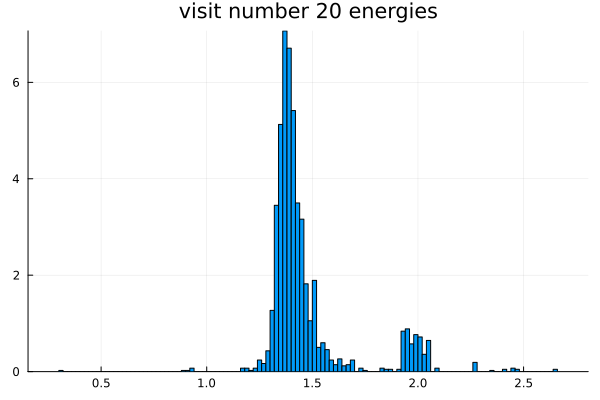

In [51]:
p = histogram( test , title="visit number $visit_num_test energies", legend=false,
                normalized=true)
display(p)

In [ ]:
data = test[1]  # Replace with your actual data


## use Julia KDE

In [63]:
data_kde = kde( data );

In [53]:
pdf( data_kde, 1:0.5:2.5)

4-element Vector{Float64}:
 4.04588125242917e-6
 1.4491467187199085
 0.6723035908867346
 0.001053310245476057

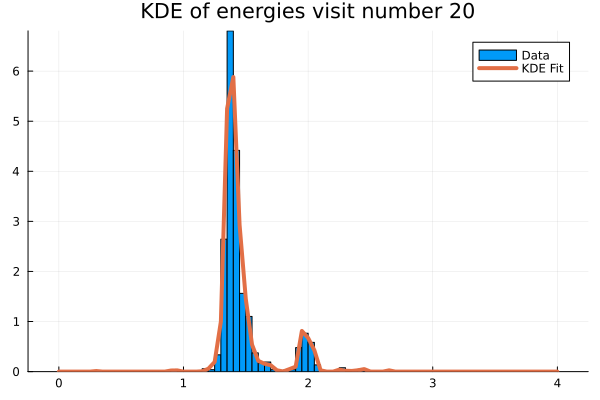

In [55]:
binz = 0:0.05:4
histogram(data, label="Data", normalized=true, bins=binz )
plot!(binz, pdf( data_kde, binz) , lw=LINE_WIDTH, 
    label="KDE Fit", 
    title="KDE of energies visit number $visit_num_test")

In [43]:
pdf( data_kde, [1.4, 2.2])

2-element Vector{Float64}:
 5.881899636799513
 2.232545161220056e-6

In [48]:
# normalized
integral, error = quadgk(x -> pdf(data_kde, x), 0, 5)

(0.9999999820745388, 1.4815334008654982e-8)

In [82]:
num_bins = 50
min_range = 0
max_range = 5
bin_edges = range(min_range, max_range, length=num_bins+1)
bin_midpoints = [(bin_edges[i] + bin_edges[i+1]) / 2 for i in 1:num_bins];

In [105]:
function bin_probability(energies_kde, low, high)
    integral, _ = quadgk(x -> pdf(energies_kde, x), low, high)
    return integral
end

function calculate_derivative(normalized_probabilities, bin_edges)
    num_bins = length(normalized_probabilities)
    bin_midpoints = [(bin_edges[i] + bin_edges[i+1]) / 2 for i in 1:num_bins]
    derivative_probabilities = zeros(num_bins)

    # First bin (forward difference)
    derivative_probabilities[1] = (normalized_probabilities[2] - normalized_probabilities[1]) / (bin_midpoints[2] - bin_midpoints[1])

    # Last bin (backward difference)
    derivative_probabilities[end] = (normalized_probabilities[end] - normalized_probabilities[end-1]) / (bin_midpoints[end] - bin_midpoints[end-1])

    # Middle bins (central difference)
    for i in 2:num_bins-1
        delta_prob = normalized_probabilities[i+1] - normalized_probabilities[i-1]
        delta_bin = bin_midpoints[i+1] - bin_midpoints[i-1]
        derivative_probabilities[i] = delta_prob / delta_bin
    end

    return derivative_probabilities
end

calculate_derivative (generic function with 1 method)

In [124]:
visit_entropies = []
visit_temperatures = []
visit_S_T_dic = Dict()

for visit_num in eachindex(energy_dict)
    energies = energy_dict[ visit_num ][1]
    energies_kde = kde( energies )
    probabilities = [bin_probability(energies_kde, bin_edges[i], bin_edges[i+1]) for i in 1:num_bins]
    prob_sum = sum(probabilities)
    normalized_probabilities = probabilities ./ prob_sum
    entropy = sum( [ p > 0 ? (-1)*p*log(p) : 0.0 for p in normalized_probabilities ] )
    
    derivative_probabilities = calculate_derivative(normalized_probabilities, bin_edges)
    
    epsilon = 1e-10  # Threshold for handling small probabilities
    temperatures_tmp = []

    for ind in 1:length(normalized_probabilities)
        p = max(normalized_probabilities[ind], epsilon)  # Ensure p is not too small
        dp = derivative_probabilities[ind]
        temperature_tmp = dp * log(p)
        temperature_tmp = isnan(temperature_tmp) ? 0 : temperature_tmp
        push!(temperatures_tmp, temperature_tmp)
    end
    
    sum_temperatures_tmp = sum(temperatures_tmp)
    temperature = sum_temperatures_tmp != 0 ? -1 / sum_temperatures_tmp : 0  # Avoid division by zero
    
    push!(visit_entropies, entropy)
    push!(visit_temperatures, temperature)
end

In [129]:
visit_heats = []

for visit_num in 2:length(energy_dict)
    T_mean = abs(visit_temperatures[visit_num-1] - visit_temperatures[visit_num]) / abs(log( visit_temperatures[visit_num-1] / visit_temperatures[visit_num] ))
    dS = abs( visit_entropies[visit_num-1] - visit_entropies[visit_num] )
    
    heat = T_mean * dS   
    push!(visit_heats, heat)
end

In [130]:
visit_heats

30-element Vector{Any}:
 0.005689039343365147
 0.0036956963834335653
 0.025385294817650738
 0.02819655246118977
 0.0005787283316156975
 0.05756721804119896
 0.027964270472630278
 0.00889314898370872
 0.015820932262049867
 0.005567489907132316
 0.014057063192633593
 0.03507537478791903
 0.044351990199423603
 ⋮
 0.10002343112789276
 0.15413130944988762
 0.011698164576398919
 0.014335736615648954
 0.008558901886075712
 0.039816475264791866
 0.03850099036468808
 0.0229321020957269
 0.04104679996803849
 0.02874479166087818
 0.09134425701244511
 0.10078597438289005

# OLD APPROACHES

## R dirichlet processes

In [ ]:
R"library(dirichletprocess)"

In [ ]:
R"""
fit_and_get_density = function(data, points) {
    # Create and fit a Dirichlet process model
    # dp_fit <- DirichletProcessGaussian(data, alphaPriors = c(alpha, alpha))
    dp_fit <- DirichletProcessGaussian(data)
    dp_fit <- Fit(dp_fit, 200)  # Fit the model with a specified number of iterations

    # Get the likelihood function for the fitted model
    likelihood_func <- LikelihoodFunction(dp_fit)

    # Calculate the likelihood (proxy for density) at each point
    densities = sapply(points, function(point) {
        likelihood_func(point)
    })

    return(densities)
}
"""

In [ ]:
# julia_data = rand(1000);
julia_data = vcat( [rand(100) .+ 5]..., [rand(100) .+ 20]... )
x_points = collect(0 : 0.1 : 30);
@rput julia_data
@rput x_points;
dpfit = R"fit_and_get_density(julia_data, x_points)"
Rdensities = rcopy( dpfit )

plot(x_points, Rdensities )

## R KDE

In [ ]:
julia_data = data
x_points = collect(0 : 0.1 : 5);
@rput julia_data
@rput x_points;
dpfit = R"fit_and_get_density(julia_data, x_points)"
Rdensities = rcopy( dpfit )
plot(x_points, Rdensities )

## Julia Gaussian Mixture Model

In [ ]:
data_t = Array(data');
#using gaussian mixture models
model = GMM(2, data)  # 3 indicates the number of components

avll( model , reshape(data, :, 1)  )
function my_AIC(avll,k,N)
    return 2*k - (N*avll)
end

function gmm_density(point)
    # Extract parameters from the GMM model
    means = model.μ  # Means of the components
    covars = model.Σ  # Covariances of the components
    weights = model.w  # Mixture weights

    total_density = 0
    # Calculate the density for each component and sum them up
    for i in 1:length(weights)
        component_density = pdf(Normal(means[i], sqrt(covars[i])), point)
        total_density += weights[i] * component_density
    end

    return total_density
end

points = [3.40,1.4,0.1]
gmm_density.(points)

binz = 0:0.05:4
histogram(data, label="Data", normalized=true, bins=binz )
plot!(binz, gmm_density.(binz), lw=4, label="GMM Fit")

In [ ]:
data_dist_sigma = 0.05

@model function finite_mixture_model(data, K)
    N = length(data)  # Number of data points
    σ = 1.0  # Standard deviation for each component (can be adjusted)

    # Priors for the mixture components
    μ = Vector{Real}(undef, K)
    for k in 1:K
        μ[k] ~ Normal(0, data_dist_sigma)
    end
    # Dirichlet prior for the mixing proportions
    θ ~ Dirichlet(ones(K))
    # Mixture model
    for i in 1:N
        z = rand(Categorical(θ))
        @addlogprob! logpdf(Categorical(θ), z)
        
        data[i] ~ Normal(μ[z], σ)
    end
end

data = test[1]  # Replace with your actual data
# Number of mixture components
K = 4  # Adjust this based on your data
# Instantiate the model
model = finite_mixture_model(data, K)
# Sample from the posterior
chain = sample(model, NUTS(), 100)

# Number of components in your model
# Initialize arrays to store samples
μ_samples = Array{Float64}(undef, length(chain), K)
θ_samples = Array{Float64}(undef, length(chain), K)

# Extract samples for each component
for k in 1:K
    μ_samples[:, k] = get(chain, Symbol("μ[$k]"))[1].data[:, 1]
    θ_samples[:, k] = get(chain, Symbol("θ[$k]"))[1].data[:, 1]
end
# Example: Select first few samples
num_samples_to_use = 100  # Adjust as needed
μ_selected = μ_samples[1:num_samples_to_use, :]
θ_selected = θ_samples[1:num_samples_to_use, :]

In [ ]:
data = test[1]
# Function to compute the density of the mixture model at a given point
function mixture_density(x, μ_samples, θ_samples)
    K = size(μ_samples, 2)
    density = 0.0
    for k in 1:K
        component_density = mean([pdf(Normal(μ_samples[i, k], data_dist_sigma), x) * θ_samples[i, k] for i in 1:size(μ_samples, 1)])
        density += component_density
    end
    return density
end

# Generate points for plotting
x_range = minimum(data):0.1:maximum(data)
y_range = [mixture_density(x, μ_samples, θ_samples) for x in x_range]

# Plotting
plot(x_range, y_range, label="Fitted Mixture Distribution", lw=2)
histogram!(data, bins=30, alpha=0.5, label="Data Histogram", normalized=true)
xlabel!("Data")
ylabel!("Density")
title!("Dirichlet Process Mixture Model Fit")

In [ ]:
#for the temperature
function calculate_derivative(normalized_probabilities, bin_edges)
    num_bins = length(normalized_probabilities)
    bin_midpoints = [(bin_edges[i] + bin_edges[i+1]) / 2 for i in 1:num_bins]
    derivative_probabilities = zeros(num_bins)

    # First bin (forward difference)
    derivative_probabilities[1] = (normalized_probabilities[2] - normalized_probabilities[1]) / (bin_midpoints[2] - bin_midpoints[1])

    # Last bin (backward difference)
    derivative_probabilities[end] = (normalized_probabilities[end] - normalized_probabilities[end-1]) / (bin_midpoints[end] - bin_midpoints[end-1])

    # Middle bins (central difference)
    for i in 2:num_bins-1
        delta_prob = normalized_probabilities[i+1] - normalized_probabilities[i-1]
        delta_bin = bin_midpoints[i+1] - bin_midpoints[i-1]
        derivative_probabilities[i] = delta_prob / delta_bin
    end

    return derivative_probabilities
end